# 02. Exploratory Data Analysis

## Objective

The goal of this notebook is to explore patterns and relationships
within the MovieLens 32M dataset.

We will investigate:

* Rating distribution
* Rating activity over time
* Movie popularity
* Movie rating quality
* User activity
* Genre distribution
* Movie release years
* Relationship between popularity and ratings

These findings will help guide our data preprocessing
and recommendation-system design.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Load the datasets
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
MOVIELENS_DIR = PROJECT_DIR / "data" / "raw" / "ml-32m"

movies = pd.read_csv(
    MOVIELENS_DIR / "movies.csv"
)

ratings = pd.read_csv(
    MOVIELENS_DIR / "ratings.csv",
    dtype={
        "userId": "int32",
        "movieId": "int32",
        "rating": "float32",
        "timestamp": "int64"
    }
)

tags = pd.read_csv(
    MOVIELENS_DIR / "tags.csv",
    dtype={
        "userId": "int32",
        "movieId": "int32",
        "tag": "string",
        "timestamp": "int64"
    }
)

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [8]:
# Dataset Overview
print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)
print("Tags shape:", tags.shape)

print("\nMovies columns:", movies.columns.tolist())
print("Ratings columns:", ratings.columns.tolist())
print("Tags columns:", tags.columns.tolist())

Movies shape: (87585, 3)
Ratings shape: (32000204, 4)
Tags shape: (2000072, 4)

Movies columns: ['movieId', 'title', 'genres']
Ratings columns: ['userId', 'movieId', 'rating', 'timestamp']
Tags columns: ['userId', 'movieId', 'tag', 'timestamp']


In [9]:
# Rating Distribution
rating_counts = ratings["rating"].value_counts().sort_index()

print(rating_counts)

rating
0.5     525132
1.0     946675
1.5     531063
2.0    2028622
2.5    1685386
3.0    6054990
3.5    4290105
4.0    8367654
4.5    2974000
5.0    4596577
Name: count, dtype: int64


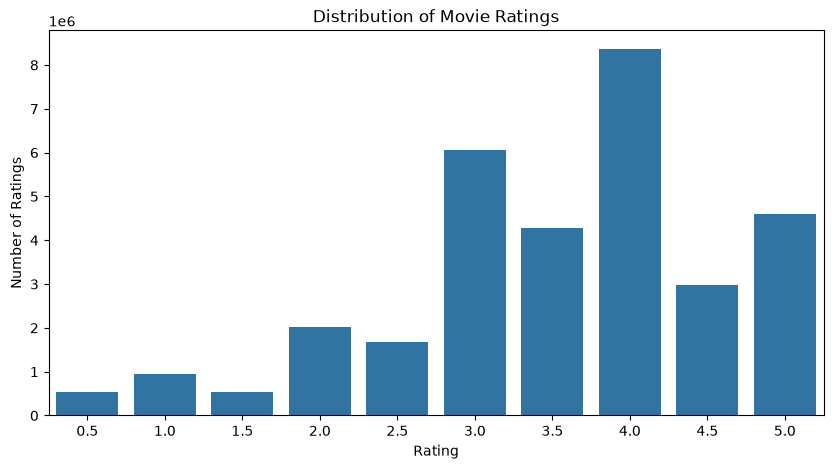

In [11]:
# visualization of rating distribution
plt.figure(figsize=(10, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

In [12]:
# rating percentage
rating_percentages = (
    ratings["rating"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(rating_percentages.round(2))

rating
0.5     1.64
1.0     2.96
1.5     1.66
2.0     6.34
2.5     5.27
3.0    18.92
3.5    13.41
4.0    26.15
4.5     9.29
5.0    14.36
Name: proportion, dtype: float64


In [13]:
# Average Rating by Year
ratings["datetime"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s"
)

ratings["year"] = ratings["datetime"].dt.year

yearly_rating_stats = (
    ratings.groupby("year")["rating"]
    .agg(["count", "mean"])
)

yearly_rating_stats

,count,mean
year,,
1995,4,3.750000
1996,1571368,3.546181
1997,685388,3.588809
1998,301691,3.514003
1999,1174629,3.616688
2000,1912322,3.576486
2001,1160098,3.533513
2002,849762,3.484735
2003,1011000,3.473930


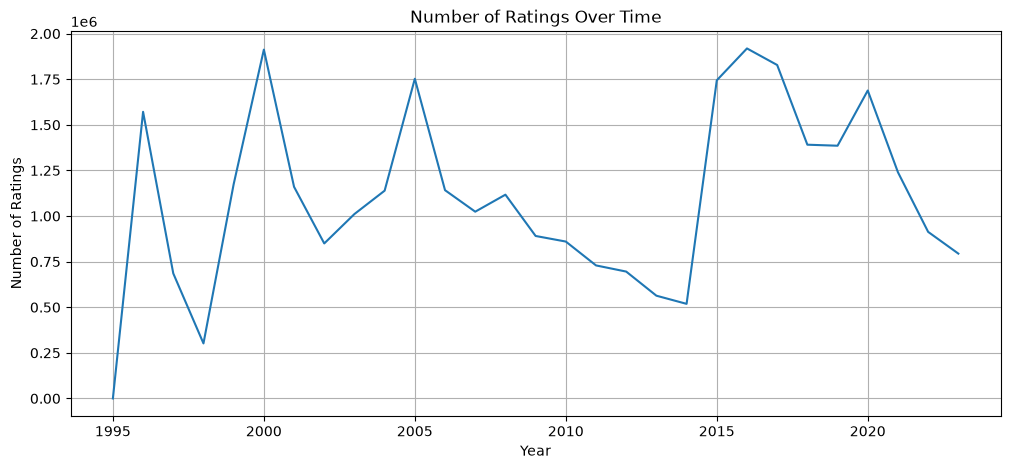

In [14]:
# Visualize Rating Activity Over Time
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_rating_stats.index,
    yearly_rating_stats["count"]
)

plt.title("Number of Ratings Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Ratings")
plt.grid(True)
plt.show()

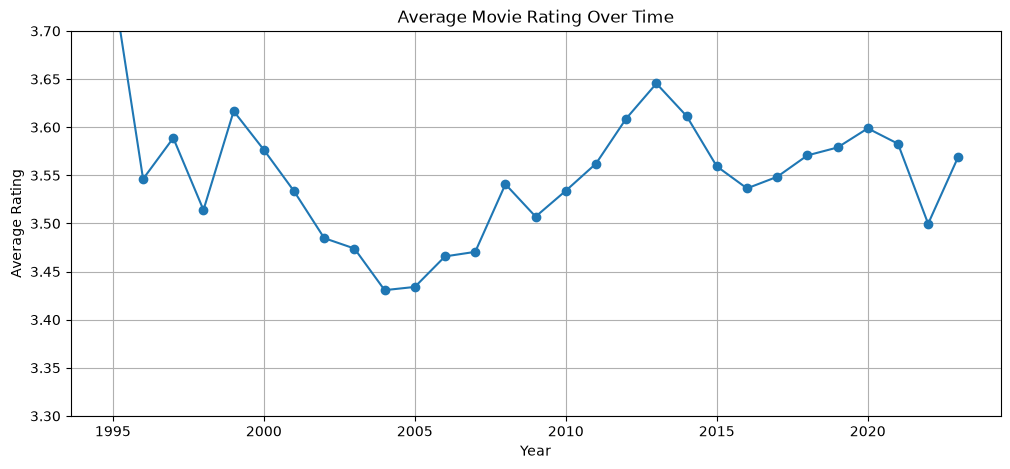

In [15]:
# Average Rating Over Time
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_rating_stats.index,
    yearly_rating_stats["mean"],
    marker="o"
)

plt.title("Average Movie Rating Over Time")
plt.xlabel("Year")
plt.ylabel("Average Rating")
plt.ylim(3.3, 3.7)
plt.grid(True)
plt.show()

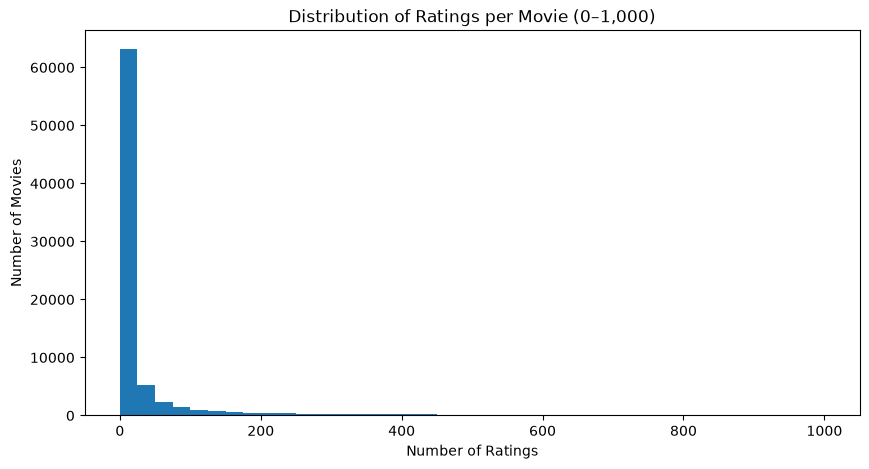

In [21]:
# Ratings per Movie
plt.figure(figsize=(10, 5))

plt.hist(
    ratings_per_movie,
    bins=40,
    range=(0, 1000)
)

plt.title("Distribution of Ratings per Movie (0–1,000)")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")
plt.show()

In [22]:
#Percentage of Movies with ≤1,000 Ratings
percentage_under_1000 = (
    (ratings_per_movie <= 1000).mean() * 100
)

print(
    f"Movies with 1,000 or fewer ratings: "
    f"{percentage_under_1000:.2f}%"
)

Movies with 1,000 or fewer ratings: 94.79%


In [25]:
popularity_groups = pd.cut(
    ratings_per_movie,
    bins=[0, 10, 50, 100, 500, 1000, 5000, 10000, np.inf],
    labels=[
        "1-10",
        "11-50",
        "51-100",
        "101-500",
        "501-1000",
        "1001-5000",
        "5001-10000",
        "10001+"
    ]
)

popularity_distribution = popularity_groups.value_counts().sort_index()

print(popularity_distribution)

1-10          53911
11-50         14638
51-100         3738
101-500        5927
501-1000       1823
1001-5000      2907
5001-10000      716
10001+          772
Name: count, dtype: int64


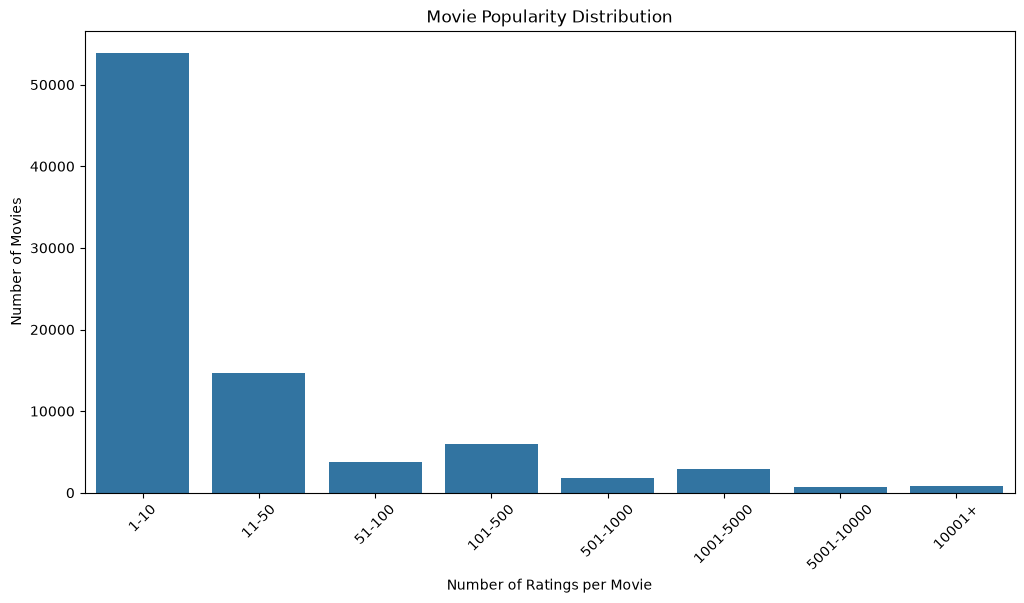

In [26]:
# Movie popularity group chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=popularity_distribution.index,
    y=popularity_distribution.values
)

plt.title("Movie Popularity Distribution")
plt.xlabel("Number of Ratings per Movie")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.show()

In [27]:
# Calculate average rating and rating count
movie_stats = ratings.groupby("movieId")["rating"].agg(
    rating_count="count",
    average_rating="mean"
)

movie_stats.head()

,rating_count,average_rating
movieId,,
1,68997,3.897438
2,28904,3.275758
3,13134,3.139447
4,2806,2.845331
5,13154,3.059602


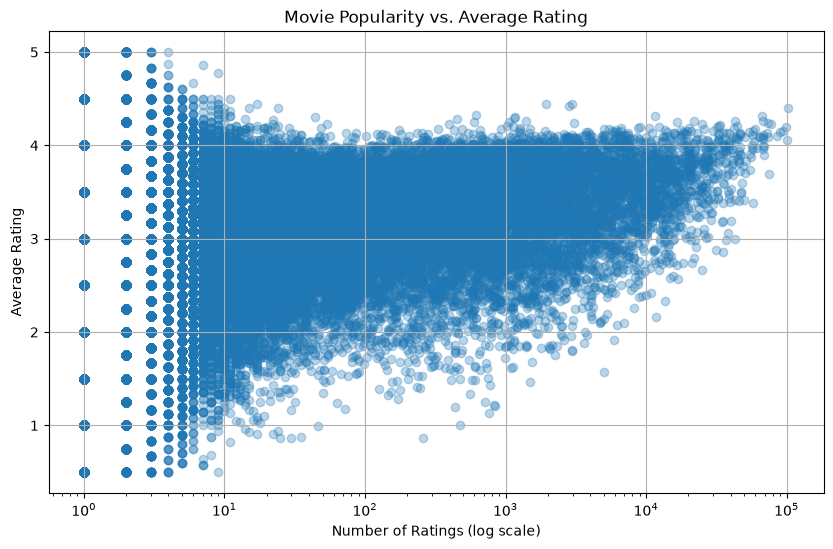

In [29]:
# Popularity vs Av. Rating
plt.figure(figsize=(10, 6))

plt.scatter(
    movie_stats["rating_count"],
    movie_stats["average_rating"],
    alpha=0.3
)

plt.xscale("log")

plt.title("Movie Popularity vs. Average Rating")
plt.xlabel("Number of Ratings (log scale)")
plt.ylabel("Average Rating")

plt.grid(True)
plt.show()

Movies with at least 100 ratings: 12191


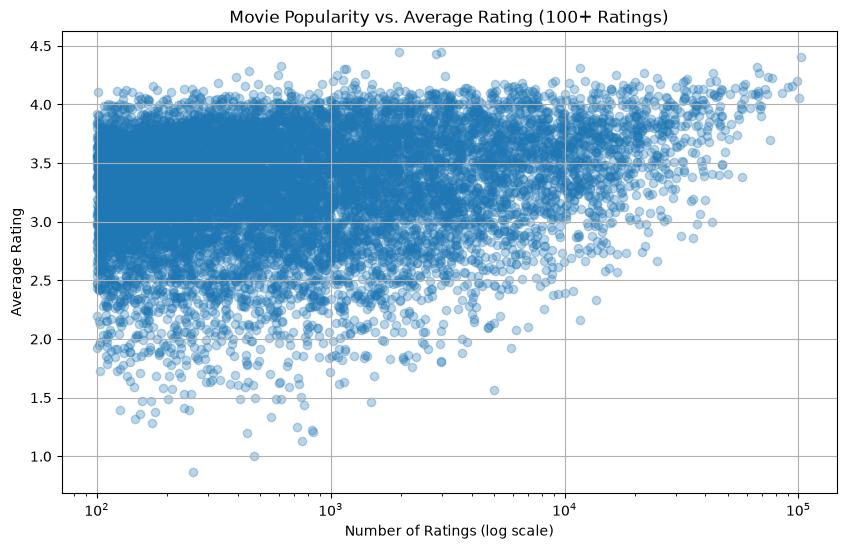

In [32]:
# Filter movies with enough ratings

movie_stats_100 = movie_stats[
    movie_stats["rating_count"] >= 100
]

print("Movies with at least 100 ratings:", len(movie_stats_100))

# Visualize Popularity vs. Average Rating (Filtered)
plt.figure(figsize=(10, 6))

plt.scatter(
    movie_stats_100["rating_count"],
    movie_stats_100["average_rating"],
    alpha=0.3
)

plt.xscale("log")

plt.title("Movie Popularity vs. Average Rating (100+ Ratings)")
plt.xlabel("Number of Ratings (log scale)")
plt.ylabel("Average Rating")

plt.grid(True)
plt.show()

In [34]:
# Find the highest-rated movies with enough ratings
top_rated_100 = (
    movie_stats_100
    .sort_values("average_rating", ascending=False)
    .head(20)
)

top_rated_100

,rating_count,average_rating
movieId,,
171011,1956,4.446830
159817,2948,4.444369
170705,2811,4.426538
318,102929,4.404614
171495,615,4.330081
858,66440,4.317030
202439,11670,4.312253
179135,1163,4.300086
198185,1140,4.298684


In [35]:
top_rated_100_with_titles = (
    top_rated_100
    .reset_index()
    .merge(
        movies[["movieId", "title"]],
        on="movieId",
        how="left"
    )
    [["movieId", "title", "rating_count", "average_rating"]]
)

top_rated_100_with_titles

,movieId,title,rating_count,average_rating
0,171011,Planet Earth II (2016),1956,4.446830
1,159817,Planet Earth (2006),2948,4.444369
2,170705,Band of Brothers (2001),2811,4.426538
3,318,"Shawshank Redemption, The (1994)",102929,4.404614
4,171495,Cosmos,615,4.330081
5,858,"Godfather, The (1972)",66440,4.317030
6,202439,Parasite (2019),11670,4.312253
7,179135,Blue Planet II (2017),1163,4.300086
8,198185,Twin Peaks (1989),1140,4.298684
9,220528,Twelve Angry Men (1954),449,4.286191


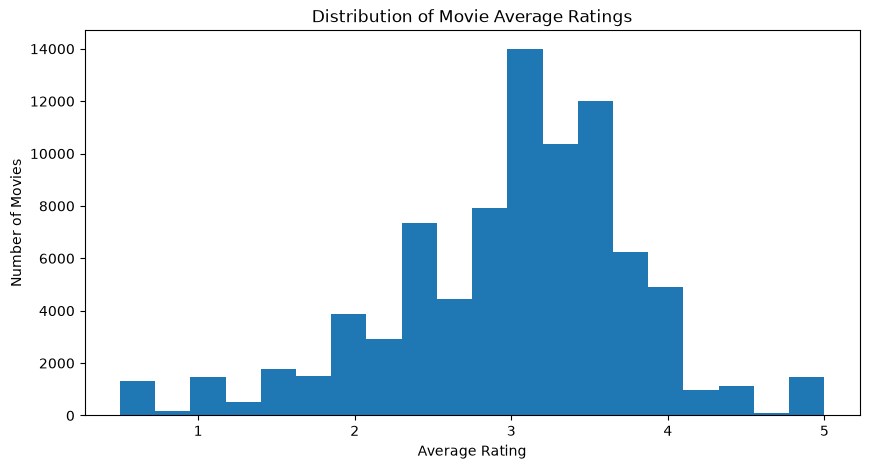

In [36]:
# Distribution of movie average ratings
plt.figure(figsize=(10, 5))

plt.hist(
    movie_stats["average_rating"],
    bins=20
)

plt.title("Distribution of Movie Average Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")

plt.show()


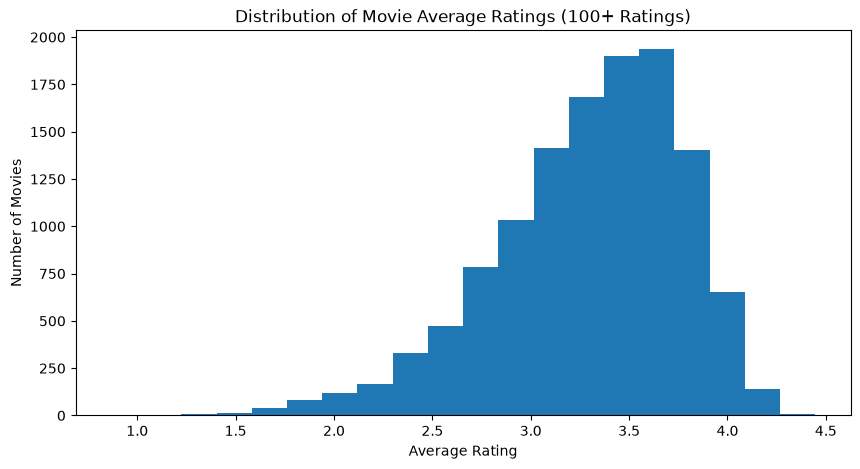

In [37]:
# Av rating with 100+ ratings
plt.figure(figsize=(10, 5))

plt.hist(
    movie_stats_100["average_rating"],
    bins=20
)

plt.title("Distribution of Movie Average Ratings (100+ Ratings)")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")

plt.show()

# Count movies by genre

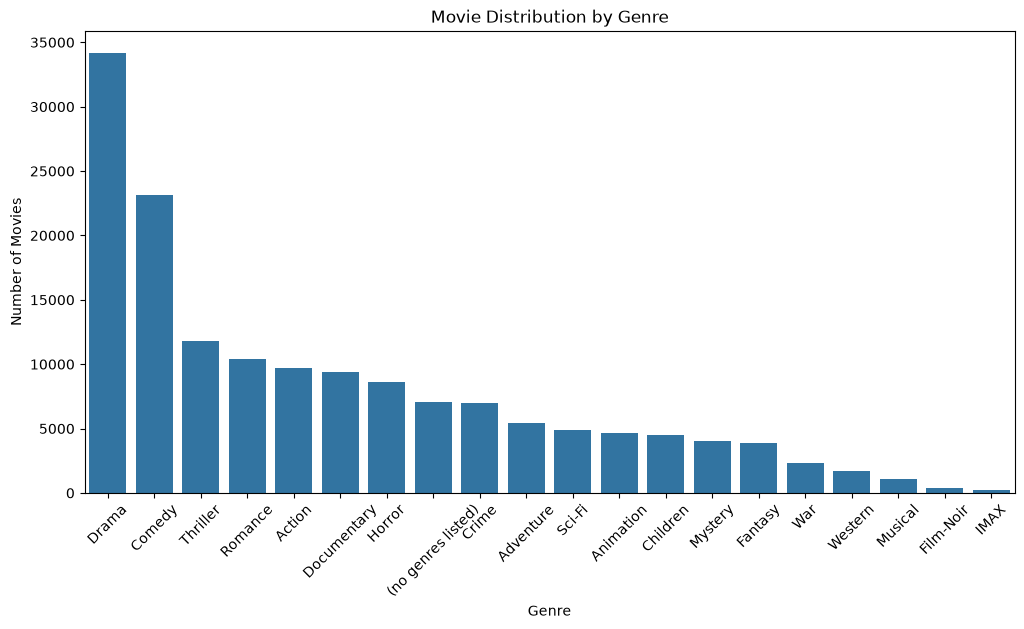

In [39]:
genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

genre_counts

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values
)

plt.title("Movie Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.show()

# Release year analysis

In [40]:
# Extract release year
movies["release_year"] = (
    movies["title"]
    .str.extract(r"\((\d{4})\)$")[0]
    .astype("Int64")
)

movies["release_year"].describe()

count        86814.0
mean     1995.351925
std        26.019943
min           1874.0
25%           1981.0
50%           2006.0
75%           2015.0
max           2023.0
Name: release_year, dtype: Float64

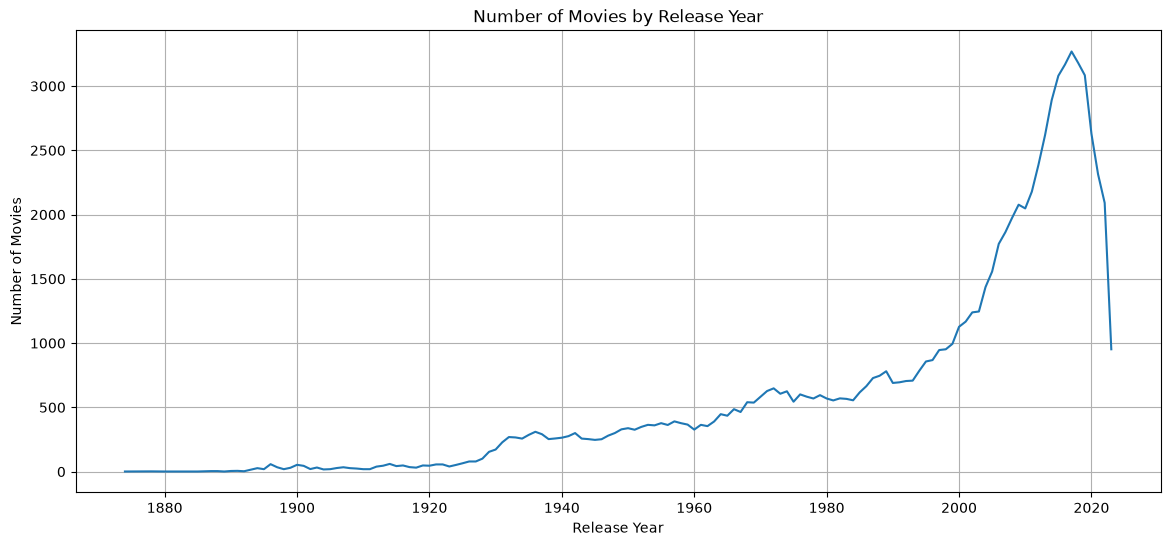

In [41]:
year_counts = (
    movies["release_year"]
    .dropna()
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    year_counts.index,
    year_counts.values
)

plt.title("Number of Movies by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.grid(True)

plt.show()

# User activity

In [45]:
ratings_per_user = ratings.groupby("userId").size()

ratings_per_user.describe()

count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33332.000000
dtype: float64

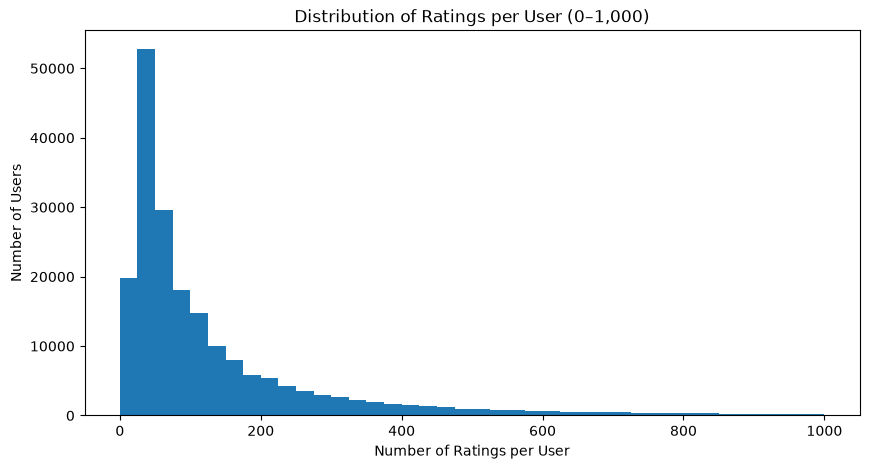

In [46]:
plt.figure(figsize=(10, 5))

plt.hist(
    ratings_per_user,
    bins=40,
    range=(0, 1000)
)

plt.title("Distribution of Ratings per User (0–1,000)")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")

plt.show()

In [47]:
# How many users have 1,000 or fewer ratings
percentage_under_1000_users = (
    (ratings_per_user <= 1000).mean() * 100
)

print(
    f"Users with 1,000 or fewer ratings: "
    f"{percentage_under_1000_users:.2f}%"
)

Users with 1,000 or fewer ratings: 98.20%


User activity is highly skewed. 98.20% of users have rated 1,000 or fewer movies, while a small number of highly active users contribute thousands or even tens of thousands of ratings. The median user has 73 ratings, compared with a mean of approximately 159 ratings.

In [48]:
# rating activity groups
user_activity_groups = pd.cut(
    ratings_per_user,
    bins=[0, 10, 50, 100, 500, 1000, 5000, 10000, np.inf],
    labels=[
        "1-10",
        "11-50",
        "51-100",
        "101-500",
        "501-1000",
        "1001-5000",
        "5001-10000",
        "10001+"
    ]
)

user_activity_distribution = (
    user_activity_groups
    .value_counts()
    .sort_index()
)

print(user_activity_distribution)

1-10              0
11-50         74360
51-100        46874
101-500       67171
501-1000       8929
1001-5000      3578
5001-10000       35
10001+            1
Name: count, dtype: int64


# Tag Analysis

In [49]:
tags_per_movie = tags.groupby("movieId").size()

tags_per_movie.describe()

count    51323.000000
mean        38.970286
std        160.935483
min          1.000000
25%          2.000000
50%          5.000000
75%         16.000000
max       6697.000000
dtype: float64

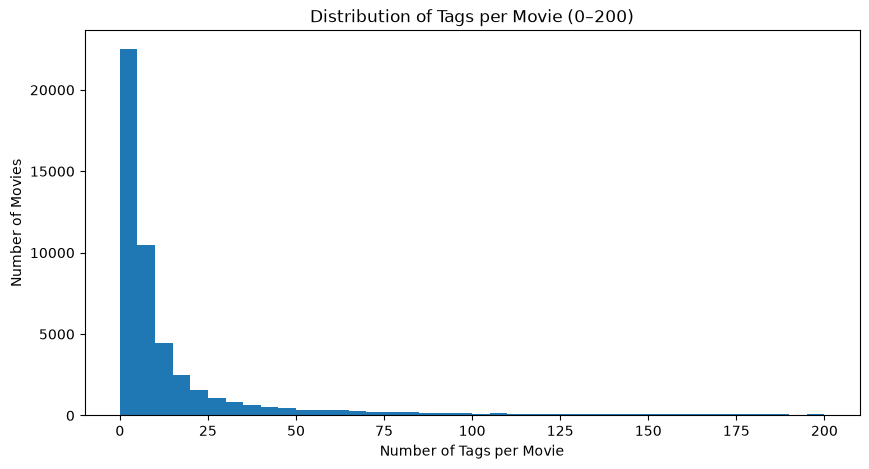

In [50]:
plt.figure(figsize=(10, 5))

plt.hist(
    tags_per_movie,
    bins=40,
    range=(0, 200)
)

plt.title("Distribution of Tags per Movie (0–200)")
plt.xlabel("Number of Tags per Movie")
plt.ylabel("Number of Movies")

plt.show()

Tag distribution is highly right-skewed. Most tagged movies have relatively few tags, while a small number of movies have a very large number of tags. The median is 5 tags per movie, compared with a mean of about 39, indicating that a small number of heavily tagged movies raise the average.

In [52]:
# Top tagged movies

top_tagged_movies = (
    tags_per_movie
    .sort_values(ascending=False)
    .head(20)
)

top_tagged_movies

movieId
296       6697
79132     6568
260       6519
2571      5722
2959      5532
109487    5477
318       4892
4226      3808
7361      3683
356       3581
593       3469
164179    3420
4878      3260
4973      3230
202439    3052
115713    3044
541       3009
48780     2972
2858      2896
74458     2845
dtype: int64

In [53]:
# Results with movie title
top_tagged_movies_with_titles = (
    top_tagged_movies
    .reset_index(name="tag_count")
    .merge(
        movies[["movieId", "title"]],
        on="movieId",
        how="left"
    )
    [["movieId", "title", "tag_count"]]
)

top_tagged_movies_with_titles

,movieId,title,tag_count
0,296,Pulp Fiction (1994),6697
1,79132,Inception (2010),6568
2,260,Star Wars: Episode IV - A New Hope (1977),6519
3,2571,"Matrix, The (1999)",5722
4,2959,Fight Club (1999),5532
5,109487,Interstellar (2014),5477
6,318,"Shawshank Redemption, The (1994)",4892
7,4226,Memento (2000),3808
8,7361,Eternal Sunshine of the Spotless Mind (2004),3683
9,356,Forrest Gump (1994),3581


In [54]:
# examine whether highly rated movies tend to have more ratings
correlation = movie_stats["rating_count"].corr(
    movie_stats["average_rating"]
)

print(f"Correlation between popularity and average rating: {correlation:.3f}")

Correlation between popularity and average rating: 0.098


The correlation between movie popularity and average rating is 0.098, indicating a very weak positive linear relationship. Therefore, popularity and rating quality should be treated as separate characteristics when designing the recommendation system.